# NEU Steel Defect Dataset: EDA & Quality Review

**Study:** Comparative Evaluation of Classical Machine Learning Algorithms for Industrial Steel Surface Defect Classification  
**Objective:** inspect the six steel-defect classes, verify image encoding and duplicates, and create figures for the academic report.

> **Leakage policy:** The `train` directory is used for all visual exploration and feature-distribution analysis. The `validation` directory is reserved as our **final held-out test set**. We inspect only its class counts, file metadata, and data-integrity information at this stage. No model training, hyperparameter tuning, or performance testing happens here.

In [1]:
from pathlib import Path
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

ROOT_HINT = os.environ.get("NEU_PROJECT_ROOT")
candidates = ([Path(ROOT_HINT).expanduser()] if ROOT_HINT else []) + [
    Path.home() / "base" / "NEU_Steel_Defects_CPU",
    Path.cwd(),
    *Path.cwd().parents,
    Path.cwd() / "NEU_Steel_Defects_CPU",
]
ROOT = next((p.resolve() for p in candidates if (p / "outputs" / "step1_dataset_manifest.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError(
        "Step 1 manifest not found. Set NEU_PROJECT_ROOT or update ROOT_HINT to the project folder."
    )
OUT = ROOT / "outputs"
OUT.mkdir(parents=True, exist_ok=True)
MANIFEST_PATH = OUT / "step1_dataset_manifest.csv"
manifest = pd.read_csv(MANIFEST_PATH)
required = {"path", "split", "label", "width", "height", "mode", "sha256"}
missing = required - set(manifest.columns)
if missing:
    raise ValueError(f"Missing manifest columns: {sorted(missing)}")
manifest["absolute_path"] = manifest["path"].map(lambda p: ROOT / p)
absent = manifest.loc[~manifest["absolute_path"].map(Path.is_file), "path"]
if not absent.empty:
    raise FileNotFoundError(f"Missing image files, example: {absent.iloc[0]}")
CLASSES = ["crazing", "inclusion", "patches", "pitted_surface", "rolled-in_scale", "scratches"]
TRAIN = manifest.query("split == 'train'").copy()
TEST = manifest.query("split == 'validation'").copy()  # held-out; only metadata audited
print("Project root:", ROOT)
print(f"Manifest: {len(manifest)} images | train: {len(TRAIN)} | held-out test: {len(TEST)}")
print("Image modes:", manifest['mode'].value_counts().to_dict())

Project root: /home/eren/base/NEU_Steel_Defects_CPU
Manifest: 1800 images | train: 1440 | held-out test: 360
Image modes: {'RGB': 1800}


## 2. Class distribution and official split

This figure shows label counts for both directories only. We do **not** inspect held-out images for model selection.

split,train,held-out test
label,,
crazing,240,60
inclusion,240,60
patches,240,60
pitted_surface,240,60
rolled-in_scale,240,60
scratches,240,60


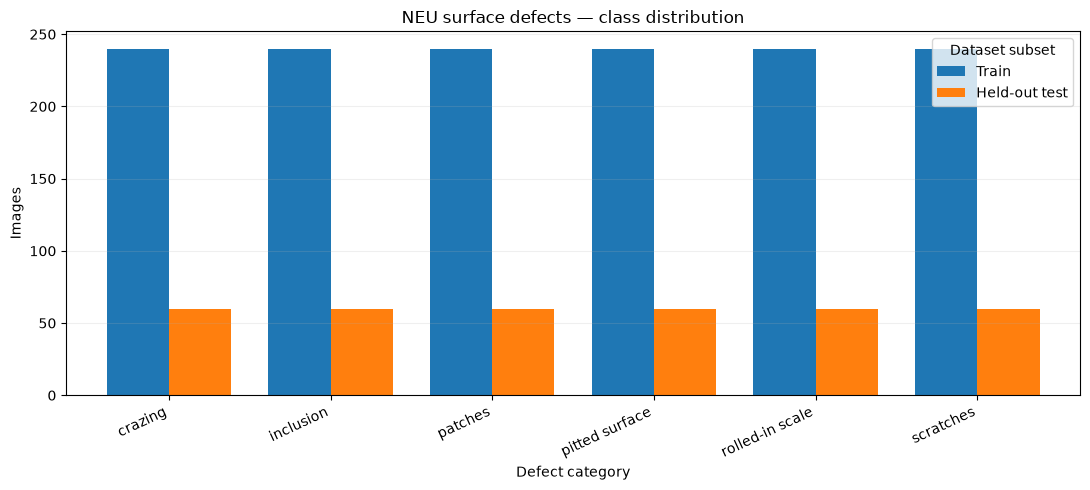

Saved: /home/eren/base/NEU_Steel_Defects_CPU/outputs/step2_class_distribution.png


In [2]:
counts = pd.crosstab(manifest["label"], manifest["split"])
counts = counts.reindex(index=CLASSES, columns=["train", "validation"], fill_value=0)
display(counts.rename(columns={"validation": "held-out test"}))

ax = counts.rename(columns={"validation": "Held-out test", "train": "Train"}).plot(
    kind="bar", figsize=(11, 5), width=0.77
)
ax.set(title="NEU surface defects — class distribution", xlabel="Defect category", ylabel="Images")
ax.set_xticklabels([s.replace("_", " ").replace("-", "-") for s in CLASSES], rotation=25, ha="right")
ax.grid(axis="y", alpha=0.20)
ax.legend(title="Dataset subset")
plt.tight_layout()
path = OUT / "step2_class_distribution.png"
plt.savefig(path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", path)

## 3. RGB warning investigation

An `RGB` JPEG is **not** necessarily a color photograph. It may store a grayscale picture as three identical channels. We'll inspect each file's encoded channel values and report whether `R == G == B` for every pixel.

In [3]:
channel_results = []
for _, rec in manifest.iterrows():
    p = rec["absolute_path"]
    with Image.open(p) as img:
        if img.mode == "RGB":
            rgb = np.asarray(img)
            same = bool(np.array_equal(rgb[:, :, 0], rgb[:, :, 1]) and
                        np.array_equal(rgb[:, :, 0], rgb[:, :, 2]))
        elif img.mode in ("L", "P"):
            same = True if img.mode == "L" else None
        else:
            same = None
    channel_results.append({
        "path": rec["path"], "split": rec["split"], "mode": rec["mode"],
        "rgb_channels_identical": same,
    })
channel_df = pd.DataFrame(channel_results)
channel_df.to_csv(OUT / "step2_channel_audit.csv", index=False)
display(channel_df.groupby(["split", "mode", "rgb_channels_identical"], dropna=False).size()
        .rename("images").reset_index())
not_identical = channel_df.loc[(channel_df["mode"] == "RGB") & (channel_df["rgb_channels_identical"] == False)]
if not not_identical.empty:
    print(f"ATTENTION: {len(not_identical)} RGB images contain non-identical channels.")
    print("Grayscale conversion is still possible, but note the color information before deciding.")
else:
    print("All RGB images inspected have identical channels (if any). Their RGB storage is not a problem.")
print("Saved: step2_channel_audit.csv")

,split,mode,rgb_channels_identical,images
0,train,RGB,True,1440
1,validation,RGB,True,360


All RGB images inspected have identical channels (if any). Their RGB storage is not a problem.
Saved: step2_channel_audit.csv


In [5]:
dups = manifest.loc[manifest.duplicated("sha256", keep=False),
                    ["sha256", "split", "label", "path"]].copy()
dups = dups.sort_values(["sha256", "split", "label", "path"]).reset_index(drop=True)
if len(dups):
    dups.insert(0, "group", pd.factorize(dups["sha256"])[0] + 1)
    display(dups.drop(columns="sha256"))
    cross_split = (dups.groupby("sha256")["split"].nunique() > 1).sum()
    cross_label = (dups.groupby("sha256")["label"].nunique() > 1).sum()
    print(f"Duplicate groups: {dups['group'].nunique()}, cross-split: {cross_split}, conflicting labels: {cross_label}")
    if cross_split:
        print("STOP: train/test exact duplication found; resolve before modeling.")
    elif (dups["split"] == "train").any():
        print("Review: training duplicates must remain together in CV folds or be deduplicated before CV.")
    else:
        print("Duplicate group is within the held-out test split; document its effect on the evaluation.")
else:
    print("No exact duplicates found.")
dups.to_csv(OUT / "step2_exact_duplicate_groups.csv", index=False)
print("Saved: step2_exact_duplicate_groups.csv")

,group,split,label,path
0,1,train,patches,data/raw/NEU-DET/train/images/patches/patches_...
1,1,train,patches,data/raw/NEU-DET/train/images/patches/patches_...


Duplicate groups: 1, cross-split: 0, conflicting labels: 0
Review: training duplicates must remain together in CV folds or be deduplicated before CV.
Saved: step2_exact_duplicate_groups.csv


## 5. Training-image gallery — three examples per class

Only **training** images are displayed. This provides useful report figures without visually exploring the held-out test cases.

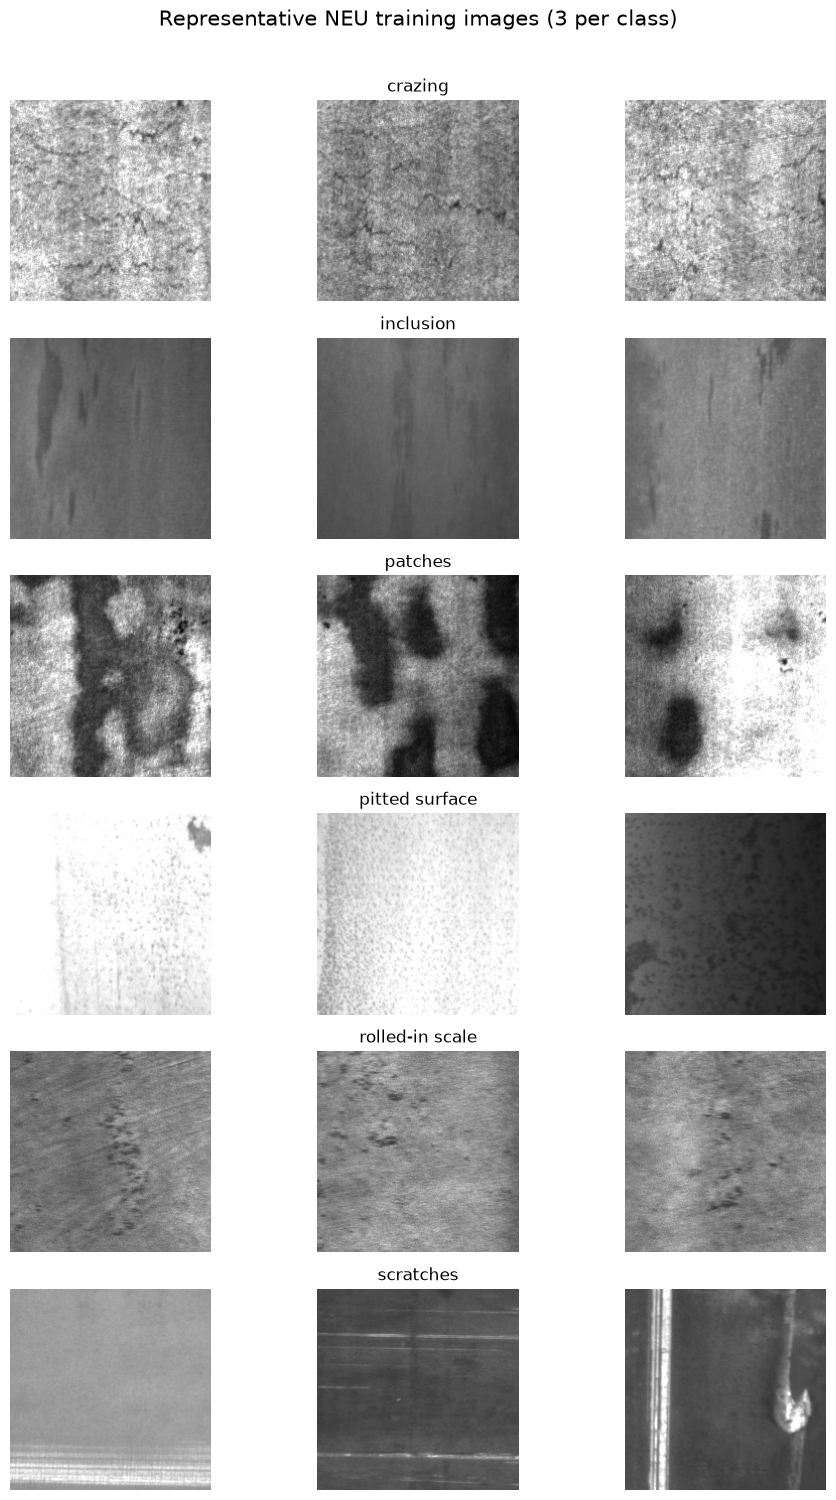

Saved: /home/eren/base/NEU_Steel_Defects_CPU/outputs/step2_train_sample_gallery.png


In [6]:
rng = np.random.default_rng(42)
fig, axes = plt.subplots(len(CLASSES), 3, figsize=(10, 15))
for row, label in enumerate(CLASSES):
    recs = TRAIN.loc[TRAIN["label"] == label].sort_values("path").reset_index(drop=True)
    if len(recs) == 0:
        raise ValueError(f"No training images for {label}")
    positions = rng.choice(len(recs), size=3, replace=(len(recs) < 3))
    for col, pos in enumerate(positions):
        rec = recs.iloc[int(pos)]
        with Image.open(rec["absolute_path"]) as img:
            gray = img.convert("L")
            axes[row, col].imshow(gray, cmap="gray", vmin=0, vmax=255)
        axes[row, col].axis("off")
        if col == 0:
            axes[row, col].set_ylabel(label.replace("_", " "), rotation=90, fontsize=10)
        axes[row, col].set_title(label.replace("_", " ") if col == 1 else "", fontsize=12)
fig.suptitle("Representative NEU training images (3 per class)", fontsize=15, y=0.997)
plt.tight_layout(rect=(0, 0, 1, 0.985))
path = OUT / "step2_train_sample_gallery.png"
plt.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)

## 6. EDA features for *training images only*
compute four **descriptive** measures on a consistently downsampled 64×64 grayscale preview: mean intensity, intensity standard deviation, P90–P10 contrast, and average horizontal/vertical gradient magnitude. These are for exploratory plots, **not yet the final feature-extraction pipeline**.

In [7]:
def describe_image(image_path: Path) -> dict:
    with Image.open(image_path) as img:
        a = np.asarray(img.convert("L").resize((64, 64), Image.Resampling.BILINEAR), dtype=np.float32)
    return {
        "mean_intensity": float(a.mean()),
        "intensity_std": float(a.std()),
        "p90_p10_contrast": float(np.percentile(a, 90) - np.percentile(a, 10)),
        "edge_strength": float((np.abs(np.diff(a, axis=0)).mean() + np.abs(np.diff(a, axis=1)).mean()) / 2),
    }

train_stats = []
for _, rec in TRAIN.iterrows():
    train_stats.append({"path": rec["path"], "label": rec["label"], **describe_image(rec["absolute_path"])})
stats = pd.DataFrame(train_stats)
stats.to_csv(OUT / "step2_training_image_statistics.csv", index=False)
summary = stats.groupby("label")[["mean_intensity", "intensity_std", "p90_p10_contrast", "edge_strength"]].agg(["mean", "std"])
display(summary.round(2))
print("Saved: step2_training_image_statistics.csv")

mean_intensity        intensity_std        p90_p10_contrast  \
                          mean    std          mean    std             mean   
label                                                                         
crazing                 135.60  27.66         23.74   6.04            61.60   
inclusion               101.84  29.24         11.56   4.13            30.49   
patches                 131.91  42.74         51.93  11.94           139.70   
pitted_surface          178.81  48.41         25.24   8.58            66.42   
rolled-in_scale         126.43  19.44         14.66   3.24            37.43   
scratches                97.98  29.71         20.76   8.55            44.31   

                       edge_strength        
                   std          mean   std  
label                                       
crazing          16.84          9.21  1.91  
inclusion        11.33          1.84  0.54  
patches          34.16          9.15  2.32  
pitted_surface   23.96          4.59  2.00  
rolled-in_scale   8.84          4.83  0.74  
scratches        21.19          3.25  1.28

Saved: step2_training_image_statistics.csv


## 7. Report-quality intensity and texture plots

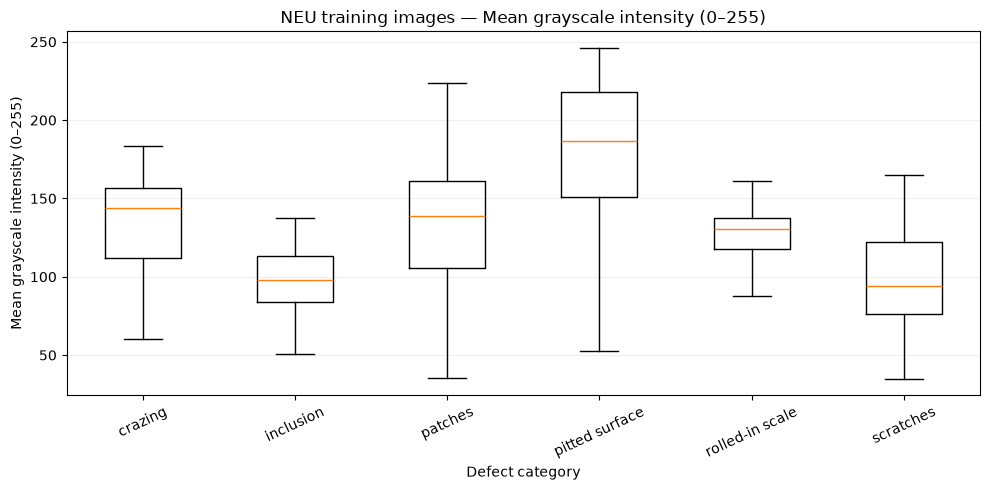

Saved: /home/eren/base/NEU_Steel_Defects_CPU/outputs/step2_mean_intensity.png


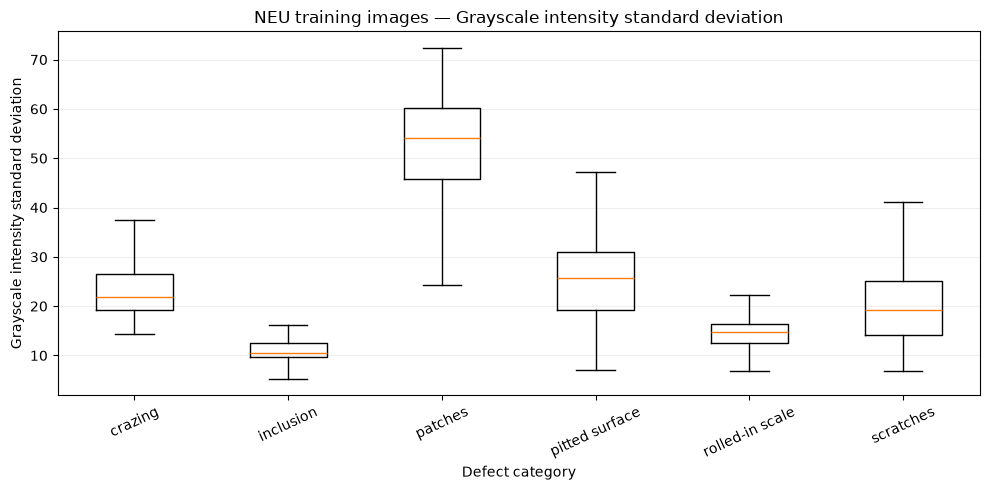

Saved: /home/eren/base/NEU_Steel_Defects_CPU/outputs/step2_intensity_std.png


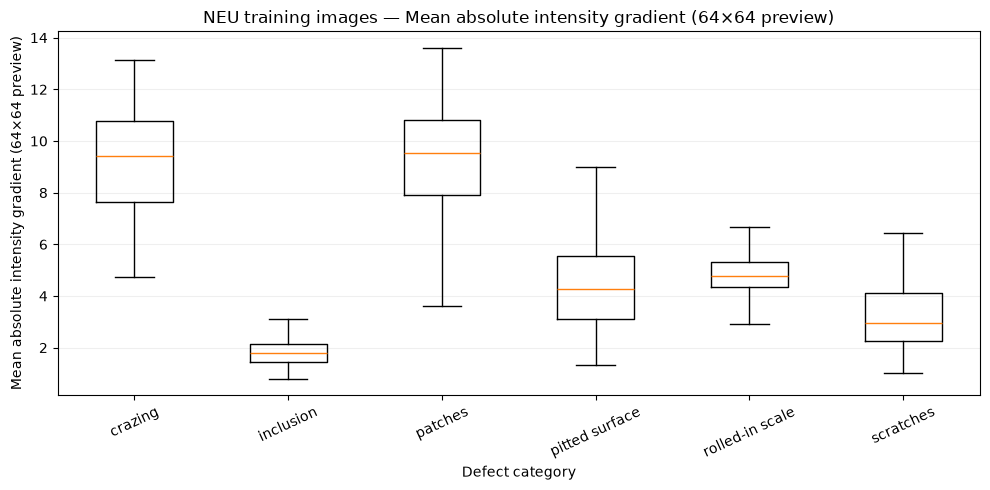

Saved: /home/eren/base/NEU_Steel_Defects_CPU/outputs/step2_edge_strength.png


In [8]:
metrics = [
    ("mean_intensity", "Mean grayscale intensity (0–255)", "step2_mean_intensity.png"),
    ("intensity_std", "Grayscale intensity standard deviation", "step2_intensity_std.png"),
    ("edge_strength", "Mean absolute intensity gradient (64×64 preview)", "step2_edge_strength.png"),
]
for key, ylabel, filename in metrics:
    fig, ax = plt.subplots(figsize=(10, 5))
    groups = [stats.loc[stats["label"] == cls, key].to_numpy() for cls in CLASSES]
    ax.boxplot(groups, tick_labels=[c.replace("_", " ") for c in CLASSES], showfliers=False)
    ax.set_title("NEU training images — " + ylabel)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Defect category")
    ax.tick_params(axis="x", labelrotation=25)
    ax.grid(axis="y", alpha=0.2)
    fig.tight_layout()
    target = OUT / filename
    fig.savefig(target, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved:", target)

In [ ]:
duplicated_groups = int(dups["sha256"].nunique()) if not dups.empty else 0
cross_split_dups = int((dups.groupby("sha256")["split"].nunique() > 1).sum()) if not dups.empty else 0
result = {
    "dataset": "NEU steel surface defect classification",
    "project_root": str(ROOT),
    "classes": CLASSES,
    "images": len(manifest),
    "train_images": len(TRAIN),
    "held_out_test_images": len(TEST),
    "input_image_modes": {str(k): int(v) for k,v in manifest["mode"].value_counts().items()},
    "rgb_nonidentical_channel_images": int(len(not_identical)),
    "exact_duplicate_groups": duplicated_groups,
    "exact_cross_split_duplicate_groups": cross_split_dups,
    "train_only_eda": True,
    "future_policy": "Use 5-fold CV on training only; reserve validation/ as final test; manage duplicate groups within CV.",
}
(OUT / "step2_eda_summary.json").write_text(json.dumps(result, indent=2), encoding="utf-8")
print(json.dumps(result, indent=2))

{
  "dataset": "NEU steel surface defect classification",
  "project_root": "/home/eren/base/NEU_Steel_Defects_CPU",
  "classes": [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
  ],
  "images": 1800,
  "train_images": 1440,
  "held_out_test_images": 360,
  "input_image_modes": {
    "RGB": 1800
  },
  "rgb_nonidentical_channel_images": 0,
  "exact_duplicate_groups": 1,
  "exact_cross_split_duplicate_groups": 0,
  "train_only_eda": true,
  "future_policy": "Use 5-fold CV on training only; reserve validation/ as final test; manage duplicate groups within CV."
}

Step 2 complete. Next: HOG + LBP features and leakage-safe ML pipelines.
